# Tweet Sentiment Classification

Classifies the overall sentiment of a tweet as positive, negative or neutral, using the SemEval 2017 Task 4 (Subtask A) corpus.

1. **Setup**: imports and settings
2. **Data**: loading and cleaning the tweets
3. **Scoring**: the task's official metric, macro-F1 over the positive and negative classes
4. **Features**: the four feature sets (V1–V4) for the classic models
5. **Classic models**: MaxEnt and LinearSVC, plus the optional full grid search
6. **LSTM**: a bidirectional LSTM with attention on GloVe embeddings
7. **BERTweet**: a fine-tuned tweet transformer
8. **Results**: every model on dev and the three test sets, and scoring new files

Running the notebook writes the results table to `Results.csv`, the figures to `figures/` and, with the full search on, the grid-search results to `Model Stats.csv`.

## 1. Setup

In [1]:
# ---Standard Library---
import copy
import csv
import gzip
import os
import re
import string
from collections import Counter

# ---Data Processing---
import numpy as np
import pandas as pd

# ---NLP---
import nltk
for pkg in ['stopwords', 'opinion_lexicon', 'wordnet', 'omw-1.4']:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords, opinion_lexicon
from nltk.stem import WordNetLemmatizer
from nltk.sentiment.util import mark_negation
import contractions
import emoji

# ---Feature Engineering---
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.pipeline import FeatureUnion, make_pipeline
from sklearn.preprocessing import FunctionTransformer, MaxAbsScaler
from scipy.sparse import csr_matrix

# ---Visualisation---
import matplotlib.pyplot as plt
import seaborn as sns

# ---Eval---
from sklearn.metrics import f1_score, confusion_matrix

# ---Model Selection---
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# ---Traditional Models---
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# ---Deep Learning---
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm

In [2]:
# ---Paths---
data_path = "semeval-tweets"           # tweet files, plus embeddings/ (GloVe) and lexicons/ (NRC)
figures_dir = "figures"
results_path = "Results.csv"
model_stats_path = "Model Stats.csv"   # written by the full grid search

SPLIT_FILES = {
    "train": "twitter-training-data.txt",
    "dev":   "twitter-dev-data.txt",
    "test1": "twitter-test1.txt",
    "test2": "twitter-test2.txt",
    "test3": "twitter-test3.txt",
}
SCORED_SPLITS = ["dev", "test1", "test2", "test3"]

# ---Options---
# Set to True to re-run the full grid search over every model and feature set (slow)
full_model_search = False
# Set to False to skip fine-tuning BERTweet (needs a GPU to be practical; downloads ~540 MB on the first run)
run_bertweet = True

# ---Labels and device---
LABELS = ["positive", "negative", "neutral"]
LABEL_IDS = {label: i for i, label in enumerate(LABELS)}
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

os.makedirs(figures_dir, exist_ok=True)

## 2. Data

Each file has one tweet per line: `tweet_id`, `sentiment` and `text`, separated by tabs. Every file is loaded once and cleaned in two ways:
- `clean`: lowercased, contractions expanded, URLs, mentions and `#` removed, emojis turned into words, punctuation and stop words (except negations) removed, repeated letters shortened, lemmatised. Used by the classic models (V1–V3) and the LSTM.
- `clean_neg`: the same, with words after a negation marked `_NEG` up to the next punctuation mark. Used by V4.

BERTweet uses the raw `text`.

In [3]:
lemmatizer = WordNetLemmatizer()

# Build stop words list but keep negation words
stop_words = set(stopwords.words('english'))
stop_words.difference_update({'no', 'not', 'nor'})

punct_table = str.maketrans('', '', string.punctuation)

def clean_text(text, mark_neg=False):
    """
    Clean a tweet for the models.
    With mark_neg=True, words after a negation get a _NEG suffix up to the next
    punctuation mark (e.g. "not good. great" -> "not good_NEG great"). Only V4 uses this.
    """
    try:
        # Convert text to lowercase
        text = text.lower()

        # Expand contractions (e.g., "can't" -> "cannot")
        text = contractions.fix(text)

        # Remove URLs
        text = re.sub(r'http\S+', '', text)

        # Remove mentions (e.g., @username)
        text = re.sub(r'@\w+', '', text)

        # Remove the hashtag symbol but keep the word (or you could choose to keep it)
        text = re.sub(r'#', '', text)

        # Convert emojis to words (e.g., "😊" -> "smiling face with smiling eyes")
        text = emoji.demojize(text, delimiters=(" ", " ")).replace("_", " ")

        if mark_neg:
            # mark_negation doesn't recognise "cannot"
            text = re.sub(r'\bcannot\b', 'can not', text)
            # Keep clause punctuation as separate tokens so the negation stops there
            text = re.sub(r'([.:;!?])', r' \1 ', text)
            # Add _NEG to every word after a negation, up to the next punctuation mark
            tokens = mark_negation(text.split())
        else:
            tokens = text.split()

        cleaned_tokens = []
        for token in tokens:
            # Set the _NEG suffix aside so the steps below see the plain word
            word, suffix = (token[:-4], "_NEG") if token.endswith("_NEG") else (token, "")

            # Remove punctuation
            word = word.translate(punct_table)

            # Normalize elongated words (e.g., "soooo" -> "so")
            word = re.sub(r'(.)\1{2,}', r'\1', word)

            # Remove stop words (keeping negation words since they're removed from stop_words above)
            if not word or word in stop_words:
                continue

            # Lemmatize, then put the suffix back
            cleaned_tokens.append(lemmatizer.lemmatize(word) + suffix)

        # Re-join tokens into a cleaned string
        return " ".join(cleaned_tokens)

    except:
        print(text)
        return text


def read_tweets(path):
    """
    Read a tab-separated tweet file (tweet_id, sentiment, text).
    Tweet IDs are read as text so leading zeros are kept (they're matched against the gold labels),
    and quote characters are ignored so tweets containing " aren't merged together.
    """
    return pd.read_csv(path, names=["tweet_id", "sentiment", "text"], delimiter="\t",
                       dtype={"tweet_id": str}, quoting=csv.QUOTE_NONE)

def load_split(path):
    """Read a tweet file and add its cleaned text ("clean") and negation-marked text ("clean_neg")."""
    df = read_tweets(path)
    df["clean"] = df["text"].apply(clean_text)
    df["clean_neg"] = df["text"].apply(lambda x: clean_text(x, mark_neg=True))
    return df

In [4]:
data = {split: load_split(os.path.join(data_path, file)) for split, file in SPLIT_FILES.items()}
y_train = data["train"]["sentiment"]

for split, df in data.items():
    mix = ", ".join(f"{label} {share:.0%}" for label, share in df["sentiment"].value_counts(normalize=True).items())
    print(f"{split:>5}: {len(df):>6,} tweets ({mix})")

data["dev"][["sentiment", "text", "clean"]].sample(5, random_state=1)

train: 45,101 tweets (neutral 46%, positive 35%, negative 18%)
  dev:  2,000 tweets (neutral 46%, positive 35%, negative 19%)
test1:  3,531 tweets (neutral 43%, positive 42%, negative 16%)
test2:  1,853 tweets (positive 53%, neutral 36%, negative 11%)
test3:  2,379 tweets (positive 43%, neutral 41%, negative 15%)


,sentiment,text,clean
674,neutral,"I wish I had a SS tshirt, I would wear it righ...",wish s tshirt would wear right tomorrow
1699,negative,"""The real enemy we are facing: Back in January...",real enemy facing back january attack paris ch...
1282,positive,"""His voice will take you to an other planet ,...",voice take planet rolling stone still give chi...
1315,positive,Check out the Japan top chart: Kurt Cobain sol...,check japan top chart kurt cobain solo album s...
1210,positive,"""Good peak at presidential candidates. Carly F...",good peak presidential candidate carly fiorina...


## 3. Scoring

The task's official scorer: macro-F1 over the **positive** and **negative** classes (F1PN). Neutral isn't scored directly, but mistakes involving it still lower the other two scores. A tweet with no prediction counts as neutral.

`score_model` scores a model on dev and the three test sets and records the results for the table in section 8.

In [5]:
# Skeleton: Evaluation code for the test sets
def read_test(testset):
    '''
    readin the testset and return a dictionary
    :param testset: str, the file name of the testset to compare
    '''
    id_gts = {}
    with open(testset, 'r', encoding='utf8') as fh:
        for line in fh:
            fields = line.split('\t')
            tweetid = fields[0]
            gt = fields[1]

            id_gts[tweetid] = gt

    return id_gts


def evaluate(id_preds, testset, classifier, verbose=True):
    '''
    print and return the macro-F1 score of {'positive', 'negative'} between preds and testset
    :param id_preds: a dictionary of predictions formated as {<tweetid>:<sentiment>, ... }
    :param testset: str, the file name of the testset to compare
    :classifier: str, the name of the classifier
    '''
    id_gts = read_test(testset)

    acc_by_class = {}
    for gt in ['positive', 'negative', 'neutral']:
        acc_by_class[gt] = {'tp': 0, 'fp': 0, 'tn': 0, 'fn': 0}

    catf1s = {}

    ok = 0
    for tweetid, gt in id_gts.items():
        if tweetid in id_preds:
            pred = id_preds[tweetid]
        else:
            pred = 'neutral'

        if gt == pred:
            ok += 1
            acc_by_class[gt]['tp'] += 1
        else:
            acc_by_class[gt]['fn'] += 1
            acc_by_class[pred]['fp'] += 1

    catcount = 0
    itemcount = 0
    macro = {'p': 0, 'r': 0, 'f1': 0}
    micro = {'p': 0, 'r': 0, 'f1': 0}
    semevalmacro = {'p': 0, 'r': 0, 'f1': 0}

    microtp = 0
    microfp = 0
    microtn = 0
    microfn = 0
    for cat, acc in acc_by_class.items():
        catcount += 1

        microtp += acc['tp']
        microfp += acc['fp']
        microtn += acc['tn']
        microfn += acc['fn']

        p = 0
        if (acc['tp'] + acc['fp']) > 0:
            p = float(acc['tp']) / (acc['tp'] + acc['fp'])

        r = 0
        if (acc['tp'] + acc['fn']) > 0:
            r = float(acc['tp']) / (acc['tp'] + acc['fn'])

        f1 = 0
        if (p + r) > 0:
            f1 = 2 * p * r / (p + r)

        catf1s[cat] = f1

        n = acc['tp'] + acc['fn']

        macro['p'] += p
        macro['r'] += r
        macro['f1'] += f1

        if cat in ['positive', 'negative']:
            semevalmacro['p'] += p
            semevalmacro['r'] += r
            semevalmacro['f1'] += f1

        itemcount += n

    micro['p'] = float(microtp) / float(microtp + microfp)
    micro['r'] = float(microtp) / float(microtp + microfn)
    micro['f1'] = 2 * float(micro['p']) * micro['r'] / float(micro['p'] + micro['r'])

    semevalmacrof1 = semevalmacro['f1'] / 2

    if verbose:
        print(testset + ' (' + classifier + '): %.3f' % semevalmacrof1)
    return semevalmacrof1


def plot_confusion_matrix(y_true, y_pred, classes=LABELS, title="Confusion Matrix", filename=None):
    """Plot a confusion matrix, and save it to figures_dir when a filename is given."""
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title(title)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    if filename:
        plt.savefig(os.path.join(figures_dir, filename), dpi=100, bbox_inches="tight")
    plt.show()

predictors = {}   # short model name -> function(df) returning a predicted label per tweet
results = {}      # display name -> {split: F1PN}

def score_model(key, display_name, predict):
    """Score predict(df) on dev and the test sets with the official scorer, and record the results."""
    predictors[key] = predict
    results[display_name] = {}
    for split in SCORED_SPLITS:
        df = data[split]
        preds = dict(zip(df["tweet_id"], predict(df)))
        results[display_name][split] = evaluate(preds, os.path.join(data_path, SPLIT_FILES[split]), key)
    return results[display_name]

## 4. Features (classic models)

- **V1**: unigram and bigram counts, plus counts of positive and negative words from the Bing Liu opinion lexicon.
- **V2**: TF-IDF, plus the same lexicon counts.
- **V3**: word TF-IDF (1–2 grams) and character TF-IDF (3–5 characters within words), plus the same lexicon counts.
- **V4**: V3 on the negation-marked text, plus scores from two Twitter lexicons (NRC Hashtag and NRC Emoticon). Negated words count with the opposite sentiment. V4 is skipped if the NRC lexicons aren't downloaded (see the README).

Each feature set is fitted once on the training tweets. `features(version, df)` then builds the same features for any dataset.

In [6]:
positive_words = set(opinion_lexicon.positive())
negative_words = set(opinion_lexicon.negative())

def lexicon_features(text):
    tokens = text.split()
    pos_count = sum(1 for token in tokens if token in positive_words)
    neg_count = sum(1 for token in tokens if token in negative_words)
    return [pos_count, neg_count]

def load_nrc_lexicon(path):
    """Load an NRC lexicon file (term<tab>score<tab>numPositive<tab>numNegative) as {term: score}."""
    opener = gzip.open if path.endswith(".gz") else open
    scores = {}
    with opener(path, "rt", encoding="utf-8") as f:
        for line in f:
            term, score, *_ = line.rstrip("\n").split("\t")
            # Skip @mentions and #hashtags, since cleaning removes mentions and the # symbol
            if term.startswith(("@", "#")):
                continue
            scores[term] = float(score)
    return scores

def lexicon_features_v4(text):
    """
    Lexicon features for V4 (10 numbers per tweet): the Bing Liu positive and negative
    counts, then for each NRC lexicon (Hashtag, Emoticon) the number of positive-scoring
    words, the total score, the highest score and the last scored word's score.
    Words marked _NEG count with the opposite sentiment.
    """
    pos_count = neg_count = 0
    lex_scores = [[], []]
    for token in text.split():
        negated = token.endswith("_NEG")
        word = token[:-4] if negated else token

        # Bing Liu: a negated positive word counts as negative, and the other way round
        if word in positive_words:
            if negated:
                neg_count += 1
            else:
                pos_count += 1
        elif word in negative_words:
            if negated:
                pos_count += 1
            else:
                neg_count += 1

        for scores, lex in zip(lex_scores, (hashtag_lex, emoticon_lex)):
            if word in lex:
                scores.append(-lex[word] if negated else lex[word])

    features = [pos_count, neg_count]
    for scores in lex_scores:
        features += [sum(x > 0 for x in scores), sum(scores),
                     max(scores, default=0), scores[-1] if scores else 0]
    return features

def v4_lex_matrix(texts):
    return csr_matrix(np.array([lexicon_features_v4(t) for t in texts], dtype=float))

def lexicon_matrix(texts):
    """Bing Liu positive and negative word counts for each text, as a sparse matrix (V1-V3)."""
    return csr_matrix(np.array([lexicon_features(t) for t in texts]))

# NRC Twitter lexicons for V4
lex_dir = os.path.join(data_path, "lexicons")
hashtag_path  = os.path.join(lex_dir, "NRC-Hashtag-Sentiment-Lexicon-v0.1", "unigrams-pmilexicon.txt.gz")
emoticon_path = os.path.join(lex_dir, "NRC-Emoticon-Lexicon-v1.0", "Emoticon-unigrams.txt")
use_v4 = os.path.exists(hashtag_path) and os.path.exists(emoticon_path)

if use_v4:
    hashtag_lex  = load_nrc_lexicon(hashtag_path)
    emoticon_lex = load_nrc_lexicon(emoticon_path)
    print(f"Lexicon sizes: hashtag {len(hashtag_lex):,}, emoticon {len(emoticon_lex):,}")
    print("Negation example:", clean_text("I don't like this movie. But the music was great!", mark_neg=True))
else:
    print("V4 skipped: NRC lexicons not found in", lex_dir, "(see README)")

Lexicon sizes: hashtag 39,545, emoticon 44,125
Negation example: not like_NEG movie_NEG music great


In [7]:
def word_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2)

def char_tfidf():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True, min_df=2)

# version -> (feature builder, text column it reads)
FEATURES = {
    "V1": (FeatureUnion([("counts", CountVectorizer(ngram_range=(1, 2))),
                         ("lexicon", FunctionTransformer(lexicon_matrix))]), "clean"),
    "V2": (FeatureUnion([("tfidf", TfidfVectorizer()),
                         ("lexicon", FunctionTransformer(lexicon_matrix))]), "clean"),
    "V3": (FeatureUnion([("word", word_tfidf()),
                         ("char", char_tfidf()),
                         ("lexicon", FunctionTransformer(lexicon_matrix))]), "clean"),
}
if use_v4:
    # Lexicon totals can be well above 1, so they're scaled to [-1, 1] like the TF-IDF values
    FEATURES["V4"] = (FeatureUnion([("word", word_tfidf()),
                                    ("char", char_tfidf()),
                                    ("lexicon", make_pipeline(FunctionTransformer(v4_lex_matrix), MaxAbsScaler()))]),
                      "clean_neg")

X_train = {version: builder.fit_transform(data["train"][column]) for version, (builder, column) in FEATURES.items()}

def features(version, df):
    """Build a fitted feature set for any dataset."""
    builder, column = FEATURES[version]
    return builder.transform(df[column])

for version, X in X_train.items():
    print(f"{version}: training matrix {X.shape}")

V1: training matrix (45101, 352699)
V2: training matrix (45101, 44927)
V3: training matrix (45101, 154217)
V4: training matrix (45101, 159239)


## 5. Classic models

Each model is grid-searched with stratified 3-fold cross-validation, scored by macro-F1, on the precomputed training features. MaxEnt on V1 and LinearSVC on V3 were the best on dev in the full search, so they're the main classic models.

In [8]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

ESTIMATORS = {
    "MaxEnt":    LogisticRegression(class_weight='balanced', max_iter=1000, solver='liblinear'),
    "LinearSVC": LinearSVC(class_weight='balanced', max_iter=500),
    "MNB":       MultinomialNB(),
    "SGD":       SGDClassifier(random_state=42, class_weight='balanced', max_iter=1000, tol=1e-3),
}

PARAM_GRIDS = {
    "MaxEnt": [
        {'penalty': ['l2'], 'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100], 'solver': ['lbfgs', 'liblinear']},
        {'penalty': ['l1'], 'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100], 'solver': ['liblinear']},
    ],
    "LinearSVC": [
        # hinge with l2 only works with dual=True; l1 only works with squared_hinge and dual=False
        {'penalty': ['l2'], 'loss': ['hinge'], 'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100], 'dual': [True]},
        {'penalty': ['l2'], 'loss': ['squared_hinge'], 'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100], 'dual': [True, False]},
        {'penalty': ['l1'], 'loss': ['squared_hinge'], 'C': [0.001, 0.01, 0.1, 1, 5, 10, 50, 100], 'dual': [False]},
    ],
    "MNB": {
        'alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0],
        'fit_prior': [True, False],
    },
    "SGD": {
        'loss': ['hinge', 'log_loss'],                           # SVM-like or logistic regression
        'penalty': ['l2', 'l1', 'elasticnet'],
        'alpha': [1e-4, 1e-3, 1e-2, 1e-1, 1, 10],                # regularisation strength
        'learning_rate': ['optimal', 'constant', 'invscaling'],
        'eta0': [0.01, 0.1, 1.0],                                # initial learning rate
    },
}

searches = {}   # (model, feature version) -> fitted GridSearchCV, so no search runs twice

def run_grid(model_name, version):
    """Grid-search a model on one feature set (cached) and return the best model."""
    key = (model_name, version)
    if key not in searches:
        grid = GridSearchCV(ESTIMATORS[model_name], PARAM_GRIDS[model_name],
                            scoring='f1_macro', cv=cv, verbose=1, n_jobs=-1)
        grid.fit(X_train[version], y_train)
        searches[key] = grid
        print(f"{model_name} {version}: best params {grid.best_params_}, cross-val macro-F1 {grid.best_score_:.4f}")
    return searches[key].best_estimator_

### MaxEnt (logistic regression) on V1

Fitting 3 folds for each of 24 candidates, totalling 72 fits


c:\Users\Dhyey\anaconda3\envs\nlp-sentiment-analysis\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


MaxEnt V1: best params {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}, cross-val macro-F1 0.6465


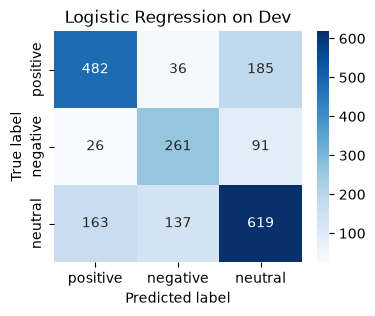

semeval-tweets\twitter-dev-data.txt (MaxEnt): 0.672
semeval-tweets\twitter-test1.txt (MaxEnt): 0.653
semeval-tweets\twitter-test2.txt (MaxEnt): 0.657
semeval-tweets\twitter-test3.txt (MaxEnt): 0.601


In [9]:
best_lr = run_grid("MaxEnt", "V1")

def maxent_predict(df):
    return best_lr.predict(features("V1", df))

plot_confusion_matrix(data["dev"]["sentiment"], maxent_predict(data["dev"]),
                      title="Logistic Regression on Dev", filename="MaxEnt_ConfMat.png")
_ = score_model("MaxEnt", "MaxEnt (V1)", maxent_predict)

### LinearSVC on V3

Fitting 3 folds for each of 32 candidates, totalling 96 fits
LinearSVC V3: best params {'C': 0.1, 'dual': False, 'loss': 'squared_hinge', 'penalty': 'l2'}, cross-val macro-F1 0.6512


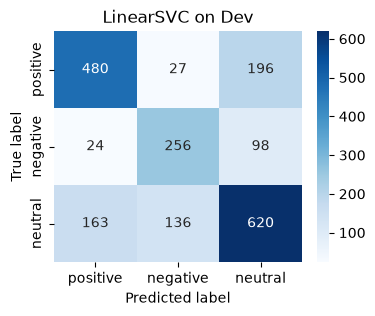

semeval-tweets\twitter-dev-data.txt (LSVC): 0.672
semeval-tweets\twitter-test1.txt (LSVC): 0.652
semeval-tweets\twitter-test2.txt (LSVC): 0.669
semeval-tweets\twitter-test3.txt (LSVC): 0.608


In [10]:
best_linear_svc = run_grid("LinearSVC", "V3")

def lsvc_predict(df):
    return best_linear_svc.predict(features("V3", df))

plot_confusion_matrix(data["dev"]["sentiment"], lsvc_predict(data["dev"]),
                      title="LinearSVC on Dev", filename="LSVC_ConfMat.png")
_ = score_model("LSVC", "LinearSVC (V3)", lsvc_predict)

### Full grid search (optional)

With `full_model_search = True`, every model is grid-searched on each feature set it's compared on, then scored on dev and the three test sets. The results are written to `Model Stats.csv`. Models are chosen on dev; the test scores are for reference only. This takes much longer, mostly because of SGD (972 fits per feature set).

In [11]:
SEARCH_FEATURES = {
    "MaxEnt":    ["V1", "V2", "V3", "V4"],
    "LinearSVC": ["V1", "V2", "V3", "V4"],
    "MNB":       ["V1", "V2"],
    "SGD":       ["V1", "V2"],
}

if full_model_search:
    rows = []
    for model_name, versions in SEARCH_FEATURES.items():
        for version in versions:
            if version not in FEATURES:   # V4 without the NRC lexicons
                continue
            best = run_grid(model_name, version)
            scores = {}
            for split in SCORED_SPLITS:
                df = data[split]
                preds = dict(zip(df["tweet_id"], best.predict(features(version, df))))
                scores[split] = evaluate(preds, os.path.join(data_path, SPLIT_FILES[split]), model_name, verbose=False)
            rows.append({
                "Features": version,
                "Model": model_name,
                "Best params": str(searches[(model_name, version)].best_params_),
                "CV macro-F1": round(searches[(model_name, version)].best_score_, 3),
                "Dev": round(scores["dev"], 3),
                "Test 1": round(scores["test1"], 3),
                "Test 2": round(scores["test2"], 3),
                "Test 3": round(scores["test3"], 3),
                "Test avg": round(np.mean([scores["test1"], scores["test2"], scores["test3"]]), 3),
            })
    model_stats = pd.DataFrame(rows)
    model_stats.to_csv(model_stats_path, index=False)
    display(model_stats)

## 6. LSTM

Frozen 100-dimension GloVe embeddings (the 5,000 most common training words) feed a 2-layer bidirectional LSTM. An attention layer weights each word's output before a linear classifier. Trained on the cleaned text with class-weighted cross-entropy and Adam, with early stopping on dev loss.

### Define Functions

In [12]:
def build_vocab(texts, max_vocab_size=5000):
    """
    Build a vocabulary dictionary from a list of cleaned text strings.
    Reserve index 0 for <PAD> and index 1 for <UNK>.
    """
    counter = Counter()
    for text in texts:
        tokens = text.split()  # assuming text is already cleaned
        counter.update(tokens)
    most_common = counter.most_common(max_vocab_size - 2)
    vocab = {"<PAD>": 0, "<UNK>": 1}
    for idx, (word, freq) in enumerate(most_common, start=2):
        vocab[word] = idx
    return vocab

def load_glove_embeddings(glove_file_path, vocab, embedding_dim=100):
    """
    Load pre-trained GloVe embeddings from a file.
    Returns an embedding matrix of shape (vocab_size, embedding_dim) as a torch.FloatTensor.
    """
    # Initialize embedding matrix with random values.
    embeddings = np.random.uniform(-0.25, 0.25, (len(vocab), embedding_dim))
    # Set the embedding for <PAD> (index 0) to zeros.
    embeddings[0] = np.zeros(embedding_dim)
    
    with open(glove_file_path, 'r', encoding='utf-8') as f:
        for line in f:
            values = line.strip().split()
            word = values[0]
            if word in vocab:
                vector = np.asarray(values[1:], dtype='float32')
                embeddings[vocab[word]] = vector
    return torch.FloatTensor(embeddings)

def text_to_sequence(text, vocab, max_length):
    """
    Convert cleaned text into a sequence of token indices.
    Pads or truncates to max_length.
    """
    tokens = text.split()  # assume text is already cleaned
    seq = [vocab.get(token, vocab["<UNK>"]) for token in tokens]
    if len(seq) < max_length:
        seq = seq + [vocab["<PAD>"]] * (max_length - len(seq))
    else:
        seq = seq[:max_length]
    return seq

### Vocab and Embeddings

In [13]:
embed_path = os.path.join(data_path, "embeddings")
train_df, dev_df = data["train"], data["dev"]

# Build vocabulary from the training text.
vocab = build_vocab(train_df["clean"].tolist(), max_vocab_size=5000)
vocab_size = len(vocab)
print("Vocabulary size:", vocab_size)

# Path to the GloVe file in the "embeddings" folder.
glove_file = os.path.join(embed_path, "glove.6B.100d.txt")
embedding_dim = 100
embedding_matrix = load_glove_embeddings(glove_file, vocab, embedding_dim=embedding_dim)
print("Embedding matrix shape:", embedding_matrix.shape)

# Calculate and set max_length according to 95th percentile of training set
token_lengths = train_df["clean"].apply(lambda x: len(x.split()))
max_length = int(np.percentile(token_lengths, 95))

def lstm_sequences(df):
    """Turn a dataset's cleaned text into a padded tensor of word indices."""
    return torch.LongTensor([text_to_sequence(text, vocab, max_length) for text in df["clean"]])

X_train_tensor = lstm_sequences(train_df)
X_val_tensor   = lstm_sequences(dev_df)

# Labels as numbers, in LABELS order (positive 0, negative 1, neutral 2)
y_train_tensor = torch.LongTensor(train_df["sentiment"].map(LABEL_IDS).values)
y_val_tensor   = torch.LongTensor(dev_df["sentiment"].map(LABEL_IDS).values)

Vocabulary size: 5000
Embedding matrix shape: torch.Size([5000, 100])


C:\Users\Dhyey\AppData\Local\Temp\ipykernel_43708\385570651.py:27: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:209.)
  y_train_tensor = torch.LongTensor(train_df["sentiment"].map(LABEL_IDS).values)


### Build LSTM Architecture

In [14]:
class LSTMWithAttention(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers,
                 bidirectional, dropout, embedding_matrix, pad_idx):
        super(LSTMWithAttention, self).__init__()
        self.pad_idx = pad_idx
        # 1. Embedding Layer: Initialize pre-trained embeddings and freeze
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.embedding.weight.data.copy_(embedding_matrix)
        self.embedding.weight.requires_grad = False
        
        # 2. Stacked LSTM Layers.
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=n_layers,
                            bidirectional=bidirectional, batch_first=True,
                            dropout=dropout if n_layers > 1 else 0)
        lstm_out_dim = hidden_dim * 2 if bidirectional else hidden_dim
        
        # 3. Attention Mechanism
        # LSTM outputs are projected to a hidden space, then scalar scores are computed
        self.attn_fc = nn.Linear(lstm_out_dim, lstm_out_dim)
        self.attn_vector = nn.Linear(lstm_out_dim, 1, bias=False)
        
        # 4. Final Classification Layer with Dropout
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(lstm_out_dim, output_dim)
    
    def forward(self, text):

        embedded = self.embedding(text)

        # Pack the sequences so the LSTM stops at each tweet's last real word and
        # never reads the padding (the backward direction would otherwise read it first).
        # Tweets that are empty after cleaning keep a length of 1 so packing still works.
        lengths = (text != self.pad_idx).sum(dim=1).clamp(min=1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(embedded, lengths, batch_first=True, enforce_sorted=False)
        packed_out, _ = self.lstm(packed)
        # Back to [batch, seq_len, hidden]; padding positions come back as zeros
        lstm_out, _ = nn.utils.rnn.pad_packed_sequence(packed_out, batch_first=True, total_length=text.size(1))
        
        # Apply attention:
        # Compute energy scores
        energy = torch.tanh(self.attn_fc(lstm_out))
        # Project to a single scalar per time step
        attn_scores = self.attn_vector(energy)
        # Ignore padding positions
        attn_scores = attn_scores.masked_fill((text == self.pad_idx).unsqueeze(-1), -1e9)
        # Softmax 
        attn_weights = F.softmax(attn_scores, dim=1) 
        # Compute the context vector as weighted sum of outputs
        context = torch.sum(lstm_out * attn_weights, dim=1)
        
        context = self.dropout(context)
        output = self.fc(context)
        return output

# --- Hyperparameters ---
vocab_size = len(vocab)     
embedding_dim = 100         
hidden_dim = 256            
output_dim = 3              
n_layers = 2                
bidirectional = True        
dropout = 0.5               
pad_idx = vocab["<PAD>"]    
batch_size = 64

# Instantiate the LSTM + Attention model.
torch.manual_seed(42)
model = LSTMWithAttention(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    hidden_dim=hidden_dim,
    output_dim=output_dim,
    n_layers=n_layers,
    bidirectional=bidirectional,
    dropout=dropout,
    embedding_matrix=embedding_matrix,
    pad_idx=pad_idx
)

print(model)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'The model has {count_parameters(model):,} trainable parameters.')

LSTMWithAttention(
  (embedding): Embedding(5000, 100, padding_idx=0)
  (lstm): LSTM(100, 256, num_layers=2, batch_first=True, dropout=0.5, bidirectional=True)
  (attn_fc): Linear(in_features=512, out_features=512, bias=True)
  (attn_vector): Linear(in_features=512, out_features=1, bias=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=512, out_features=3, bias=True)
)
The model has 2,574,851 trainable parameters.


### NN Training

Epoch 01: TrainLoss=0.9279, ValLoss=0.8487


Epoch 02: TrainLoss=0.8567, ValLoss=0.8156


Epoch 03: TrainLoss=0.8350, ValLoss=0.8018


Epoch 04: TrainLoss=0.8210, ValLoss=0.7930


Epoch 05: TrainLoss=0.8096, ValLoss=0.7799


...

Epoch 12: TrainLoss=0.7428, ValLoss=0.7472


Epoch 13: TrainLoss=0.7332, ValLoss=0.7436


Epoch 14: TrainLoss=0.7239, ValLoss=0.7509
  1 epochs without improvement in ValLoss.


Epoch 15: TrainLoss=0.7175, ValLoss=0.7437
  2 epochs without improvement in ValLoss.


Epoch 16: TrainLoss=0.7077, ValLoss=0.7618
  3 epochs without improvement in ValLoss.
Early stopping triggered after 16 epochs. No improvement in ValLoss for 3 epochs.
Restored best model from epoch 13 (ValLoss=0.7436).


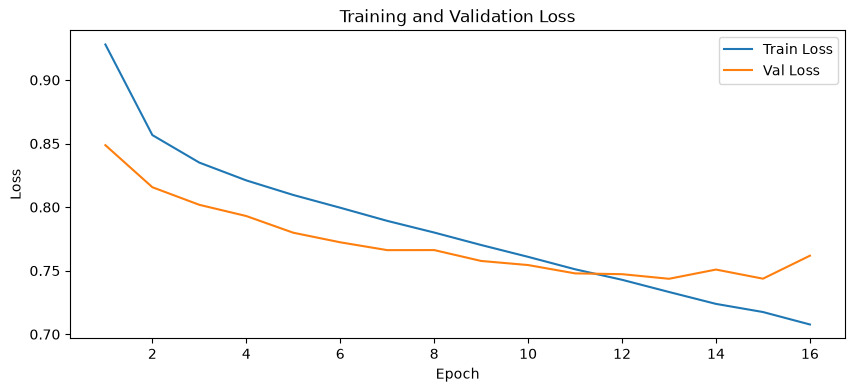

In [15]:
# Clear CUDA cache
torch.cuda.empty_cache()

model.to(device)

# Move training and validation data to device
X_train_tensor = X_train_tensor.to(device)
y_train_tensor = y_train_tensor.to(device)
X_val_tensor   = X_val_tensor.to(device)
y_val_tensor   = y_val_tensor.to(device)

# Build class weights for CrossEntropyLoss
class_counts = Counter(train_df["sentiment"])
count_dict = dict(class_counts)
total = sum(count_dict.values())
weights = [total / count_dict[i] for i in ["positive", "negative", "neutral"]]
weights = torch.FloatTensor(weights).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
criterion = torch.nn.CrossEntropyLoss(weight=weights)

def train_epoch(model, X, y, optimizer, criterion, batch_size=64):
    """
    Trains for one epoch
    """
    model.train()
    epoch_loss = 0
    num_batches = (len(X) + batch_size - 1) // batch_size

    # Shuffle so batches differ every epoch
    perm = torch.randperm(len(X), device=X.device)

    pbar = tqdm(range(0, len(X), batch_size), desc="Training Batches", total=num_batches, leave=False)
    for start_idx in pbar:
        end_idx = min(start_idx + batch_size, len(X))
        batch_idx = perm[start_idx:end_idx]
        x_batch = X[batch_idx]
        y_batch = y[batch_idx]

        optimizer.zero_grad()
        logits = model(x_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * x_batch.size(0)
        current_avg_loss = epoch_loss / end_idx
        pbar.set_postfix({"AvgLoss": f"{current_avg_loss:.4f}"})
    
    return epoch_loss / len(X)

def evaluate_nn(model, X, y, criterion, batch_size=64):
    """
    Perform validation pass
    """
    model.eval()
    epoch_loss = 0
    all_preds = []
    num_batches = (len(X) + batch_size - 1) // batch_size

    pbar = tqdm(range(0, len(X), batch_size), desc="Evaluation Batches", total=num_batches, leave=False)
    for start_idx in pbar:
        end_idx = min(start_idx + batch_size, len(X))
        x_batch = X[start_idx:end_idx]
        y_batch = y[start_idx:end_idx]

        with torch.no_grad():
            logits = model(x_batch)
            loss = criterion(logits, y_batch)
            epoch_loss += loss.item() * x_batch.size(0)
            all_preds.append(logits.argmax(dim=1).cpu().numpy())

            current_avg_loss = epoch_loss / end_idx
            pbar.set_postfix({"AvgLoss": f"{current_avg_loss:.4f}"})

    val_loss = epoch_loss / len(X)
    preds_concat = np.concatenate(all_preds)
    return val_loss, preds_concat

# Early stopping parameters
patience = 3
best_val_loss = float('inf')
epochs_without_improvement = 0

# Lists for plotting
train_losses = []
val_losses = []

num_epochs = 100
for epoch in range(num_epochs):
    # Train
    train_loss = train_epoch(model, X_train_tensor, y_train_tensor, optimizer, criterion, batch_size=batch_size)

    # Validation pass
    val_loss, val_preds = evaluate_nn(model, X_val_tensor, y_val_tensor, criterion, batch_size=batch_size)
    
    # Store for plots
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Print epoch summary
    print(f"Epoch {epoch+1:02d}: TrainLoss={train_loss:.4f}, ValLoss={val_loss:.4f}")

    # Early stopping based on val_loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())
    else:
        epochs_without_improvement += 1
        print(f"  {epochs_without_improvement} epochs without improvement in ValLoss.")
        if epochs_without_improvement >= patience:
            print(f"Early stopping triggered after {epoch+1} epochs. No improvement in ValLoss for {patience} epochs.")
            break

# Restore the weights from the epoch with the lowest validation loss
model.load_state_dict(best_model_state)
print(f"Restored best model from epoch {best_epoch} (ValLoss={best_val_loss:.4f}).")

# Plots
epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 4))
plt.plot(epochs_range, train_losses, label="Train Loss")
plt.plot(epochs_range, val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.savefig(os.path.join(figures_dir, "LSTM_ConvPlot.png"), dpi=100, bbox_inches="tight")
plt.show()

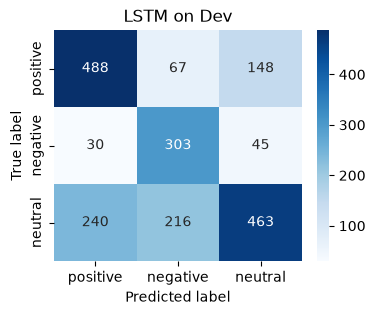

semeval-tweets\twitter-dev-data.txt (LSTM): 0.648
semeval-tweets\twitter-test1.txt (LSTM): 0.658
semeval-tweets\twitter-test2.txt (LSTM): 0.626
semeval-tweets\twitter-test3.txt (LSTM): 0.587


In [16]:
def lstm_predict(df, batch_size=64):
    """Predict a label for every tweet in a dataset with the trained LSTM."""
    model.eval()
    X = lstm_sequences(df)
    preds = []
    with torch.no_grad():
        for start_idx in range(0, len(X), batch_size):
            preds.append(model(X[start_idx:start_idx + batch_size].to(device)).argmax(dim=1).cpu())
    return [LABELS[i] for i in torch.cat(preds).tolist()]

plot_confusion_matrix(dev_df["sentiment"], lstm_predict(dev_df), title="LSTM on Dev", filename="LSTM_ConfMat.png")
_ = score_model("LSTM", "LSTM + attention", lstm_predict)

## 7. BERTweet

Fine-tunes [BERTweet](https://huggingface.co/vinai/bertweet-base), a RoBERTa-base transformer pre-trained on 850M English tweets, with a new 3-class classification layer on top.

It reads the **raw** tweets rather than the cleaned text: its tokenizer does its own light normalisation (@mentions → `@USER`, links → `HTTPURL`, emojis → text), and stop words, punctuation and word endings are kept because the model uses them. The whole model is trained for 3 epochs and the epoch with the best dev F1PN is kept.

In [17]:
if run_bertweet:
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

    bertweet_name = "vinai/bertweet-base"
    # normalization=True turns @mentions into @USER, links into HTTPURL and emojis into text
    bt_tokenizer = AutoTokenizer.from_pretrained(bertweet_name, normalization=True, use_fast=False)

    def bertweet_encode(df, max_length=128):
        """Tokenise a dataset's raw tweets. Returns token IDs, attention mask and label IDs."""
        enc = bt_tokenizer(df["text"].tolist(), padding=True, truncation=True,
                           max_length=max_length, return_tensors="pt")
        labels = torch.tensor(df["sentiment"].map(LABEL_IDS).values)
        return enc["input_ids"], enc["attention_mask"], labels

    bt_train_ids, bt_train_mask, bt_train_y = bertweet_encode(data["train"])
    bt_val_ids, bt_val_mask, bt_val_y = bertweet_encode(data["dev"])

    example = "@john I can't believe how good this is 😍 https://t.co/abc"
    print("Normalised: ", bt_tokenizer.normalizeTweet(example))
    print("Subwords:   ", bt_tokenizer.tokenize(example))
    print("Train token matrix shape:", tuple(bt_train_ids.shape))

c:\Users\Dhyey\anaconda3\envs\nlp-sentiment-analysis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Normalised:  @USER I can't believe how good this is :smiling_face_with_heart-eyes: HTTPURL
Subwords:    ['@USER', 'I', "can't", 'believe', 'how', 'good', 'this', 'is', ':smiling_face_with_heart-eyes:', 'HTTPURL']
Train token matrix shape: (45101, 84)


### Fine-tuning

In [18]:
if run_bertweet:
    torch.manual_seed(42)
    # Pre-trained BERTweet plus a new, randomly initialised 3-class classification head
    bt_model = AutoModelForSequenceClassification.from_pretrained(bertweet_name, num_labels=3).to(device)

    bt_epochs = 3
    bt_batch_size = 32
    use_amp = device.type == "cuda"  # bfloat16 mixed precision: faster and uses less GPU memory

    # Class weights, as for the other models, so the rarer negative class counts more
    bt_counts = torch.bincount(bt_train_y, minlength=3).float()
    bt_weights = (bt_counts.sum() / bt_counts).to(device)
    bt_criterion = nn.CrossEntropyLoss(weight=bt_weights)

    bt_optimizer = torch.optim.AdamW(bt_model.parameters(), lr=2e-5, weight_decay=0.01)
    bt_total_steps = bt_epochs * ((len(bt_train_ids) + bt_batch_size - 1) // bt_batch_size)
    # Warm the learning rate up over the first 10% of steps, then lower it linearly to 0
    bt_scheduler = get_linear_schedule_with_warmup(bt_optimizer, int(0.1 * bt_total_steps), bt_total_steps)

    def trim_padding(ids, mask):
        """Cut a batch down to its longest tweet, so batches of short tweets run faster."""
        length = int(mask.sum(dim=1).max())
        return ids[:, :length].to(device), mask[:, :length].to(device)

    def bertweet_logits(model, ids, mask, batch_size=128):
        """Run the model over every tweet and return the logits (on the CPU)."""
        model.eval()
        out = []
        with torch.no_grad(), torch.autocast(device.type, dtype=torch.bfloat16, enabled=use_amp):
            for start in range(0, len(ids), batch_size):
                b_ids, b_mask = trim_padding(ids[start:start + batch_size], mask[start:start + batch_size])
                out.append(model(input_ids=b_ids, attention_mask=b_mask).logits.float().cpu())
        return torch.cat(out)

    best_val_f1 = -1
    for epoch in range(bt_epochs):
        bt_model.train()
        perm = torch.randperm(len(bt_train_ids))
        epoch_loss = 0
        pbar = tqdm(range(0, len(perm), bt_batch_size), desc=f"Epoch {epoch + 1}", leave=False)
        for start in pbar:
            idx = perm[start:start + bt_batch_size]
            b_ids, b_mask = trim_padding(bt_train_ids[idx], bt_train_mask[idx])
            b_y = bt_train_y[idx].to(device)

            with torch.autocast(device.type, dtype=torch.bfloat16, enabled=use_amp):
                logits = bt_model(input_ids=b_ids, attention_mask=b_mask).logits
            loss = bt_criterion(logits.float(), b_y)

            bt_optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(bt_model.parameters(), 1.0)
            bt_optimizer.step()
            bt_scheduler.step()

            epoch_loss += loss.item() * len(idx)
            pbar.set_postfix({"AvgLoss": f"{epoch_loss / min(start + bt_batch_size, len(perm)):.4f}"})

        val_logits = bertweet_logits(bt_model, bt_val_ids, bt_val_mask)
        val_loss = F.cross_entropy(val_logits, bt_val_y, weight=bt_weights.cpu()).item()
        # The task's metric: macro-F1 over positive (0) and negative (1)
        val_f1 = f1_score(bt_val_y, val_logits.argmax(dim=1), labels=[0, 1], average="macro")
        print(f"Epoch {epoch + 1}: TrainLoss={epoch_loss / len(perm):.4f}, ValLoss={val_loss:.4f}, Val F1PN={val_f1:.3f}")

        # Keep the epoch with the best dev F1PN (copied to the CPU to save GPU memory)
        if val_f1 > best_val_f1:
            best_val_f1, bt_best_epoch = val_f1, epoch + 1
            bt_best_state = {k: v.detach().cpu().clone() for k, v in bt_model.state_dict().items()}

    bt_model.load_state_dict(bt_best_state)
    print(f"Restored best model from epoch {bt_best_epoch} (Val F1PN={best_val_f1:.3f}).")

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at vinai/bertweet-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1: TrainLoss=0.6878, ValLoss=0.5307, Val F1PN=0.757


Epoch 2: TrainLoss=0.4856, ValLoss=0.5656, Val F1PN=0.765


Epoch 3: TrainLoss=0.3783, ValLoss=0.6033, Val F1PN=0.761
Restored best model from epoch 2 (Val F1PN=0.765).


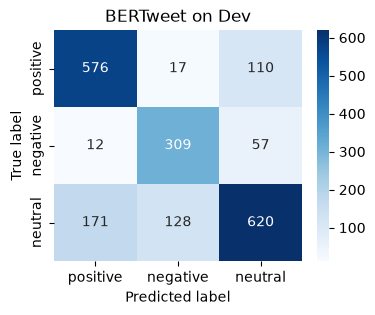

semeval-tweets\twitter-dev-data.txt (BERTweet): 0.765
semeval-tweets\twitter-test1.txt (BERTweet): 0.771
semeval-tweets\twitter-test2.txt (BERTweet): 0.780
semeval-tweets\twitter-test3.txt (BERTweet): 0.752


In [19]:
if run_bertweet:
    def bertweet_predict(df):
        """Predict a label for every tweet in a dataset with the fine-tuned BERTweet."""
        ids, mask, _ = bertweet_encode(df)
        return [LABELS[i] for i in bertweet_logits(bt_model, ids, mask).argmax(dim=1).tolist()]

    plot_confusion_matrix(data["dev"]["sentiment"], bertweet_predict(data["dev"]),
                          title="BERTweet on Dev", filename="BERTweet_ConfMat.png")
    score_model("BERTweet", "BERTweet", bertweet_predict)

## 8. Results

F1PN for every model on dev and the three test sets. The table is also written to `Results.csv`.

In [20]:
results_table = pd.DataFrame(results).T.rename(columns={"dev": "Dev", "test1": "Test 1", "test2": "Test 2", "test3": "Test 3"})
results_table["Test avg"] = results_table[["Test 1", "Test 2", "Test 3"]].mean(axis=1)
results_table = results_table.round(3)
results_table.to_csv(results_path, index_label="Model")
results_table

,Dev,Test 1,Test 2,Test 3,Test avg
MaxEnt (V1),0.672,0.653,0.657,0.601,0.637
LinearSVC (V3),0.672,0.652,0.669,0.608,0.643
LSTM + attention,0.648,0.658,0.626,0.587,0.624
BERTweet,0.765,0.771,0.780,0.752,0.768


### Scoring a new test file

`eval_on_file(file_path, select_model)` scores one of the trained models (`"MaxEnt"`, `"LSVC"`, `"LSTM"` or `"BERTweet"`) on any file in the same format. The file is cleaned and turned into features the same way as the training data, and the score is printed with the official scorer. A bare file name is looked up in `data_path`.

In [21]:
def eval_on_file(file_path, select_model="MaxEnt"):
    """Score a trained model on a tweet file (tweet_id, sentiment, text) with the official scorer."""
    if not os.path.exists(file_path):
        file_path = os.path.join(data_path, file_path)
    if select_model not in predictors:
        raise ValueError(f"Invalid model name. Choose from {list(predictors)}.")
    df = load_split(file_path)
    preds = dict(zip(df["tweet_id"], predictors[select_model](df)))
    return evaluate(preds, file_path, select_model)

# Example
eval_on_file("twitter-test1.txt", select_model="MaxEnt")

semeval-tweets\twitter-test1.txt (MaxEnt): 0.653


0.6527981791566404